In [3]:
import pickle
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, AllChem
import numpy as np
import time
import itertools
import pandas as pd
from pandas import DataFrame as df
from matplotlib import pyplot as plt
import json
import os
from tqdm.notebook import tqdm
import collections
from itertools import islice
from IPython.display import Image, display, HTML, clear_output
import ipywidgets as widgets
import random
import numpy as np
from rdkit.Chem import rdchem


from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*') 

import networkx as nx
from joblib import Parallel, delayed
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

In [4]:
def visualize_reaction (smiles):
    
    # print(smiles)
    try:
        if '>>' in smiles:
            reactant= smiles.split('>>')[0]
            product= smiles.split('>>')[1]
            
            reactant=Chem.MolToSmarts(Chem.MolFromSmiles(reactant))
            product=Chem.MolToSmarts(Chem.MolFromSmiles(product))
            smiles='>>'.join([reactant,product])
            rxn = AllChem.ReactionFromSmarts(smiles)
    
        else:
            reactant= smiles.split('>')[0]
            reagent= smiles.split('>')[1]
            product= smiles.split('>')[2]
            reactant=Chem.MolToSmarts(Chem.MolFromSmiles(reactant))
            reagent=Chem.MolToSmarts(Chem.MolFromSmiles(reagent))
            product=Chem.MolToSmarts(Chem.MolFromSmiles(product))
            smiles='>'.join([reactant,reagent,product])
            rxn = AllChem.ReactionFromSmarts(smiles)
        
        return smiles, Draw.ReactionToImage(rxn,highlightByReactant=True, subImgSize=(400, 400))
    except:
        return

In [5]:
def visualize_reaction_direct (smiles):
    
    # print(smiles)

    if '>>' in smiles:
        reactant= smiles.split('>>')[0]
        product= smiles.split('>>')[1]
        
        reactant=Chem.MolToSmarts(Chem.MolFromSmiles(reactant))
        product=Chem.MolToSmarts(Chem.MolFromSmiles(product))
        smiles='>>'.join([reactant,product])
        rxn = AllChem.ReactionFromSmarts(smiles)

    else:
        reactant= smiles.split('>')[0]
        reagent= smiles.split('>')[1]
        product= smiles.split('>')[2]
        reactant=Chem.MolToSmarts(Chem.MolFromSmiles(reactant))
        reagent=Chem.MolToSmarts(Chem.MolFromSmiles(reagent))
        product=Chem.MolToSmarts(Chem.MolFromSmiles(product))
        smiles='>'.join([reactant,reagent,product])
        rxn = AllChem.ReactionFromSmarts(smiles)
    
    return Draw.ReactionToImage(rxn,highlightByReactant=True, subImgSize=(400, 400))

In [6]:
visualize_reaction("B([c:1]1[c:2]([cH:3][c:4]([c:5]([cH:6]1)[O:7][Si:8]([CH3:9])([CH3:10])[C:11]([CH3:12])([CH3:13])[CH3:14])[O:15][CH2:16][c:17]1[cH:18][cH:19][cH:20][cH:21][cH:22]1)[O:23][CH3:24])(O)O.[CH3:25][c:26]1[cH:27][cH:28][c:29]([n:30]1-[c:31]1[n:32][c:33]([cH:34][cH:35][cH:36]1)Br)[CH3:37]>>[CH3:25][c:26]1[cH:27][cH:28][c:29]([n:30]1-[c:31]1[n:32][c:33]([cH:34][cH:35][cH:36]1)-[c:1]1[c:2]([cH:3][c:4]([c:5]([cH:6]1)[O:7][Si:8]([CH3:9])([CH3:10])[C:11]([CH3:12])([CH3:13])[CH3:14])[O:15][CH2:16][c:17]1[cH:18][cH:19][cH:20][cH:21][cH:22]1)[O:23][CH3:24])[CH3:37]")

('[#5](-[#6:1]1:[#6:2](:[#6H:3]:[#6:4](:[#6:5](:[#6H:6]:1)-[#8:7]-[Si:8](-[#6H3:9])(-[#6H3:10])-[#6:11](-[#6H3:12])(-[#6H3:13])-[#6H3:14])-[#8:15]-[#6H2:16]-[#6:17]1:[#6H:18]:[#6H:19]:[#6H:20]:[#6H:21]:[#6H:22]:1)-[#8:23]-[#6H3:24])(-[#8])-[#8].[#6H3:25]-[#6:26]1:[#6H:27]:[#6H:28]:[#6:29](:[#7:30]:1-[#6:31]1:[#7:32]:[#6:33](:[#6H:34]:[#6H:35]:[#6H:36]:1)-[#35])-[#6H3:37]>>[#6H3:25]-[#6:26]1:[#6H:27]:[#6H:28]:[#6:29](:[#7:30]:1-[#6:31]1:[#7:32]:[#6:33](:[#6H:34]:[#6H:35]:[#6H:36]:1)-[#6:1]1:[#6:2](:[#6H:3]:[#6:4](:[#6:5](:[#6H:6]:1)-[#8:7]-[Si:8](-[#6H3:9])(-[#6H3:10])-[#6:11](-[#6H3:12])(-[#6H3:13])-[#6H3:14])-[#8:15]-[#6H2:16]-[#6:17]1:[#6H:18]:[#6H:19]:[#6H:20]:[#6H:21]:[#6H:22]:1)-[#8:23]-[#6H3:24])-[#6H3:37]',
 <PIL.PngImagePlugin.PngImageFile image mode=RGB size=1600x400>)

In [7]:
untemplated_smiles_path = "../outputs/p_labeled.parquet"

In [8]:
df = pd.read_parquet(untemplated_smiles_path)  # path to your parquet file

# Count reactions per reaction name
reaction_type_count = collections.Counter(df["Name"])

# Group SMILES strings by reaction name
smiles_classified = df.groupby("Name")["SMILES"].apply(list).to_dict()

In [15]:
# all_untemplated_rxns = []

# ### makes an array of all untemplated reaction names
# with open (untemplated_smiles_path, 'r') as f:
#     for line in f:
#         all_untemplated_rxns.append(line.strip().rsplit(maxsplit=1)[-1])

In [16]:
# ### makes a dict of all untemplated reactions; key: name, value: count
# reaction_type_count = collections.Counter(all_untemplated_rxns)

In [51]:
# ### moving reaction smiles under their reaction name
# smiles_classified = {}

# with open (untemplated_smiles_path, 'r') as f:
#     for line in f:
#         line_split = line.strip().rsplit(maxsplit=1)
#         rxn_name = line_split[-1]
        
#         if rxn_name not in smiles_classified:
#             smiles_classified[rxn_name] = [line_split[0]]
#         else:
#             smiles_classified[rxn_name].append(line_split[0])

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x90 in position 9: invalid start byte

In [9]:
# with open("classify_pistachio.pkl", "wb") as f:
    # pickle.dump((reaction_type_count, smiles_classified), f)

In [21]:
with open("classify_pistachio.pkl", "rb") as f:
    reaction_type_count, smiles_classified = pickle.load(f)

In [10]:
### draws 5 reactions with rxn name
def draw5 (rxn_name):
    rxn_smiles = smiles_classified[rxn_name]
    count = 0
    for rxn in rxn_smiles:
        if(count >= 10):
            break

        image = visualize_reaction_direct(rxn)
        display(image)

        count += 1
        

In [11]:
draw5("Hiyama coupling")

ArgumentError: Python argument types in
    rdkit.Chem.rdmolfiles.MolToSmarts(NoneType)
did not match C++ signature:
    MolToSmarts(RDKit::ROMol mol, bool isomericSmiles=True)

In [12]:
def display_reaction_grid(rxn_name, mode='clean', title='SMILES'):
    smiles_list = random.sample(smiles_classified[rxn_name],min(len(smiles_classified[rxn_name]), 10))
    if not isinstance(smiles_list, list) or not smiles_list:
        return
    imgs = []
    for smiles in smiles_list:
        imgs.append(visualize_reaction(smiles))

    html = "<table><tr>"
    for i, (smarts, img) in enumerate(imgs):
        try:
            html += f"<td style='text-align:center; padding:10px'>{smarts}<br/>"
            if isinstance(img, str):
                html += f"<div>{img}</div>"
            else:
                from io import BytesIO
                import base64
                bio = BytesIO()
                img.save(bio, format="PNG")
                data = base64.b64encode(bio.getvalue()).decode()
                html += f"<img src='data:image/png;base64,{data}'/>"
            html += "</td>"
            html += "</tr><tr>"
        except:
            print("whoops")
    html += "</tr></table>"
    display(HTML(html))

In [13]:
# reaction_keys_by_count = [n[0] for n in reaction_type_count.most_common()]

# class_dropdown = widgets.Dropdown(options=list(reaction_keys_by_count), description='Type:')
# output = widgets.Output()

# # Display selected reaction sample
# def display_reaction(change=None):
#     with output:
#         output.clear_output()
#         cls = class_dropdown.value
#         print(f"Reaction class: {cls}; " + f"Count: {reaction_type_count[cls]}")

#         display_reaction_grid(cls, 'clean', title="Reaction Sample")

# class_dropdown.observe(display_reaction, names='value')

# # Show UI
# ui = widgets.VBox([
#     class_dropdown,
#     output
# ])
# display(ui)

# display_reaction()


reaction_keys_by_count = [n[0] for n in reaction_type_count.most_common()]
cleaned_options = [str(opt) for opt in reaction_keys_by_count if isinstance(opt, str)]

output = widgets.Output()

# Search box to type reaction class
class_input = widgets.Combobox(
    placeholder='Start typing...',
    options=cleaned_options,
    description='Type:',
    layout=widgets.Layout(width='50%')
)
# Display selected reaction sample
def display_reaction(change=None):
    with output:
        clear_output()
        cls = class_input.value
        if cls not in reaction_type_count:
            print(f"Reaction class '{cls}' not found.")
            return
        print(f"Reaction class: {cls}; Count: {reaction_type_count[cls]}")
        display_reaction_grid(cls, 'clean', title="Reaction Sample")

# Attach handler to search input
class_input.observe(display_reaction, names='value')

# Show UI
ui = widgets.VBox([
    class_input,
    output
])

display(ui)



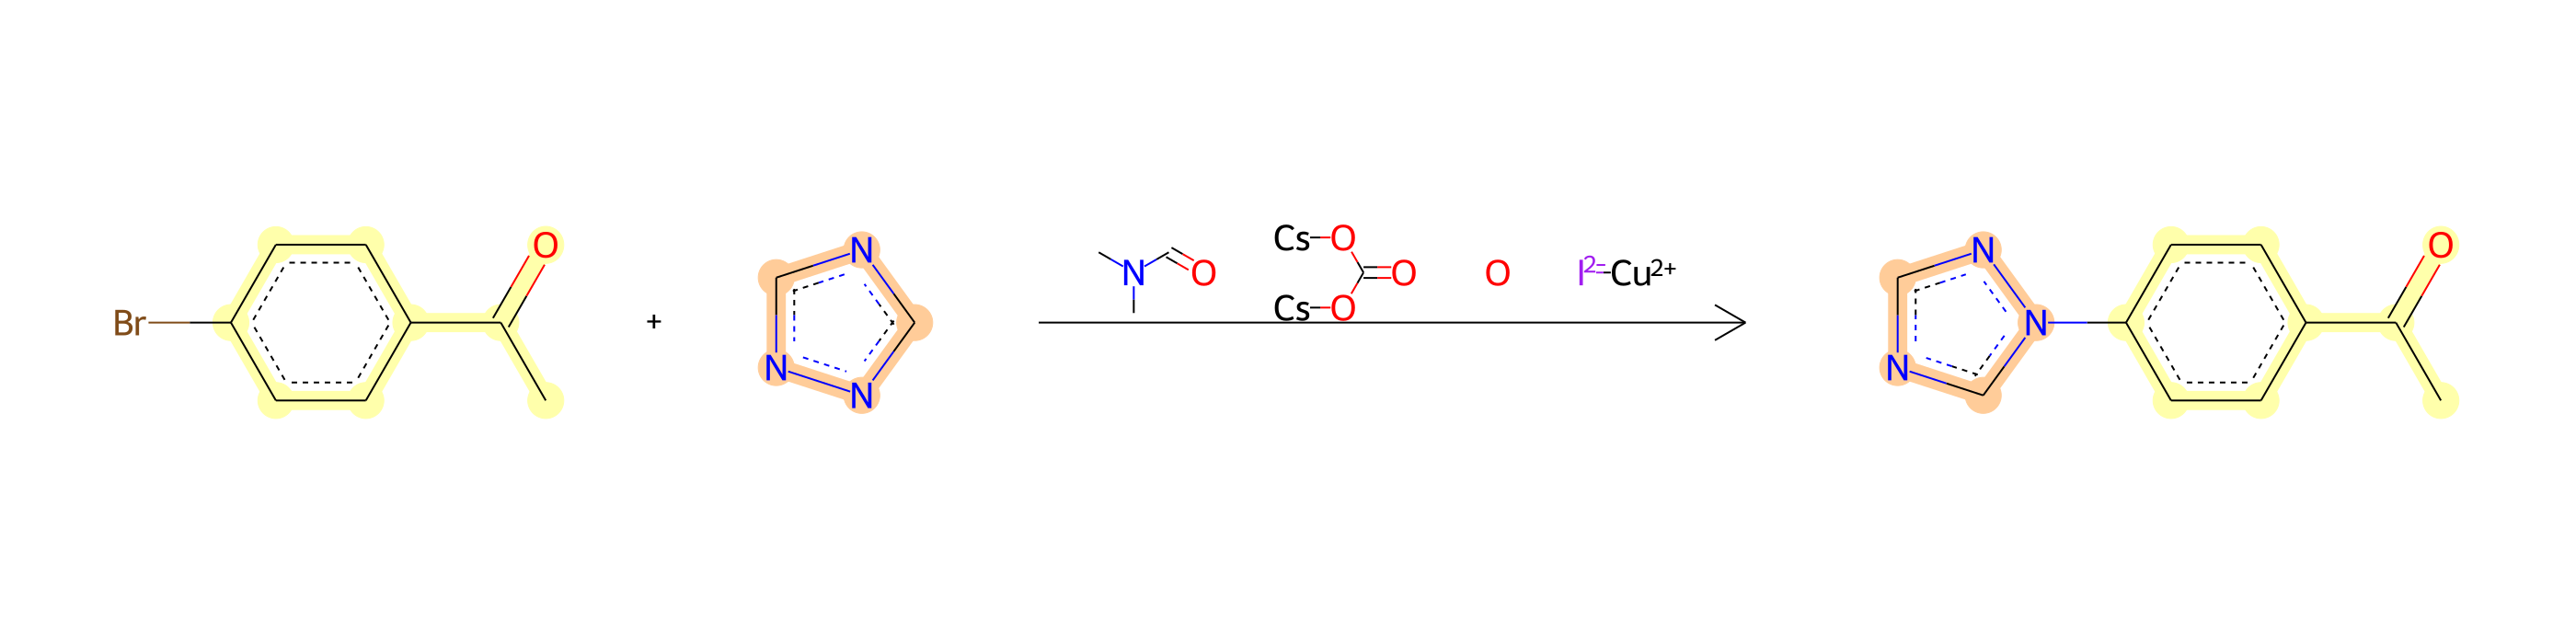

In [45]:
rxn = "[#6H3:1]-[#6:2](=[#8:3])-[#6:4]1:[#6H:5]:[#6H:6]:[#6:7](:[#6H:8]:[#6H:9]:1)-[#35].[#6H:10]1:[#7:11]:[#6H:12]:[#7:13]:[#7H:14]:1>[#6]-[#7](-[#6])-[#6]=[#8].[#6](=[#8])(-[#8]-[Cs])-[#8]-[Cs].[#8].[Cu+2]-[#53-2]>[#6H3:1]-[#6:2](=[#8:3])-[#6:4]1:[#6H:5]:[#6H:6]:[#6:7](:[#6H:8]:[#6H:9]:1)-[#7:14]1:[#6H:10]:[#7:11]:[#6H:12]:[#7:13]:1"
Draw.ReactionToImage(AllChem.ReactionFromSmarts(rxn),highlightByReactant=True, subImgSize=(700, 700))

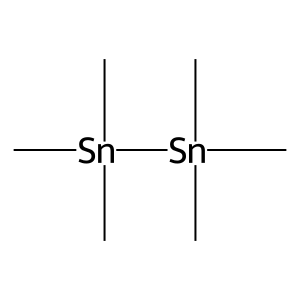

In [25]:
mol = "[#6]-[Sn](-[#6])(-[#6])-[Sn](-[#6])(-[#6])-[#6]"
Draw.MolToImage(Chem.MolFromSmarts(mol))

In [45]:
metals = [
    # Transition metals (Groups 3–12)
    "Sc", "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu", "Zn",
    "Y", "Zr", "Nb", "Mo", "Tc", "Ru", "Rh", "Pd", "Ag", "Cd",
    "Hf", "Ta", "W", "Re", "Os", "Ir", "Pt", "Au", "Hg",
    "Rf", "Db", "Sg", "Bh", "Hs", "Mt", "Ds", "Rg", "Cn",

    # Lanthanides (optional in transition set)
    "La", "Ce", "Pr", "Nd", "Pm", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu",

    # Actinides (also sometimes included)
    "Ac", "Th", "Pa", "U", "Np", "Pu", "Am", "Cm", "Bk", "Cf", "Es", "Fm", "Md", "No", "Lr",

    # P-block metals
    "Al", "Ga", "In", "Sn", "Tl", "Pb", "Bi", "Po"
]

metals = [
            3, 4, 11, 12, 13, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
            31, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 55, 56,
            57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73,
            74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 87, 88, 89, 90, 91, 92, 93,
            94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108,
            113, 114, 115, 116
        ]

ps = Chem.SmilesParserParams()
ps.removeHs = False
ps.sanitize = True

max_allowed_valences = {
            7 : 3, 
            8 : 2,
        }

ELEM_LIST = ['PAD', 'H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Na', 'Mg', 'Al', 'Si', \
            'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', \
            'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Sr', 'Y', 'Zr', 'Mo', 'Tc', 'Ru', \
            'Rh', 'Pd', 'Ag', 'In', 'Sn', 'Sb', 'Te', 'I', 'Cs', 'Ba', 'La', 'Ce', 'Eu', \
             'Yb', 'Ta', 'W', 'Os', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi']

MATRIX_PAD = -30
bt_to_electron = {Chem.rdchem.BondType.DATIVE: 2, # note: order is important!
                 Chem.rdchem.BondType.SINGLE: 2,
                 Chem.rdchem.BondType.DOUBLE: 4,
                 Chem.rdchem.BondType.TRIPLE: 6,
                 Chem.rdchem.BondType.AROMATIC: 3}

tbl = Chem.GetPeriodicTable()

def bond_features(bond):
    bt = bond.GetBondType()
    
    return bt_to_electron[bt]

def count_lone_pairs(a):
    v=tbl.GetNOuterElecs(a.GetAtomicNum())
    c=a.GetFormalCharge()
    b=sum([bond.GetBondTypeAsDouble() for bond in a.GetBonds()])
    h=a.GetTotalNumHs()
    return v-c-b-h


def fix_valence(smi):
    '''
    Takes molecule smi, msi -> fixes valence errors associated with charge/coordination by using dative bonds
    '''

    ps = Chem.SmilesParserParams()
    ps.removeHs = False
    ps.sanitize = True

    try: 
        smi = Chem.MolToSmiles(Chem.MolFromSmiles(smi, ps), isomericSmiles=False, canonical=True)
        return smi
    except rdchem.AtomValenceException: 
        settings = Chem.SmilesParserParams()
        settings.removeHs = False
        settings.sanitize = False
        mol = Chem.RWMol(Chem.MolFromSmiles(smi, settings))
        for atom in mol.GetAtoms():
            Z = atom.GetAtomicNum()
            valence = sum(bond.GetBondTypeAsDouble() for bond in atom.GetBonds())
            max_val = max_allowed_valences.get(Z, None)
            if max_val is not None and valence > max_val:
                for bond in atom.GetBonds():
                    neighbor = bond.GetOtherAtom(atom)
                    if neighbor.GetAtomicNum() in metals:

                        begin_idx = atom.GetIdx()
                        end_idx = neighbor.GetIdx()
                        mol.RemoveBond(begin_idx, end_idx)
                        mol.AddBond(begin_idx, end_idx, rdchem.BondType.DATIVE)

        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, isomericSmiles=False, canonical=True)
            
def get_BE_matrix(r):
    
    try:
        rmol = Chem.MolFromSmiles(r, ps)
    except rdchem.AtomValenceException:
        rmol = Chem.MolFromSmiles(fix_valence(r), ps)
    
    Chem.Kekulize(rmol)
    max_natoms = len(rmol.GetAtoms())
    f = np.zeros((max_natoms,max_natoms))
    
    for atom in rmol.GetAtoms():
        lone_pair = count_lone_pairs(atom)
        f[atom.GetIntProp('molAtomMapNumber') - 1, atom.GetIntProp('molAtomMapNumber') - 1] = lone_pair

    for bond in rmol.GetBonds():
        a1 = bond.GetBeginAtom().GetIntProp('molAtomMapNumber') - 1
        a2 = bond.GetEndAtom().GetIntProp('molAtomMapNumber') - 1
        f[(a1,a2)] = f[(a2,a1)] = bond_features(bond)/2 # so that bond electron diff matrix sums up to 0

    return f

In [27]:
alk_metals = ["Li", "Na", "K", "Rb", "Cs", "Fr"]

alk_e_metals = ["Be", "Mg", "Ca", "Sr", "Ba", "Ra"]

halogens = ["F", "Cl", "Br", "I"]

# def make_mol_ionic (msmi){
#     '''
#     Takes molecule smi, msi -> fixes valence errors associated with charge/coordination by using dative bonds
#     '''
    
#     settings = Chem.SmilesParserParams()
#     settings.removeHs = True
#     settings.sanitize = True
    
#     mol = Chem.RWMol(Chem.MolFromSmiles(msmi, settings))
    
#     for bond in mol.GetBonds():
            
#         start = bond.GetBeginAtom()
#         end = bond.GetEndAtom()
#         s_ind = start.GetIdx() 
#         e_ind = end.GetIdx()
#         s_sym = start.GetSymbol()
#         e_sym = end.GetSymbol()
    
#         if s_sym in alk_metals:
#             mol.RemoveBond(s_ind, e_ind)
#             start.SetFormalCharge(1)
#             end.SetFormalCharge(-1)
    
#         elif s_sym in alk_e_metals:
#             start.SetFormalCharge(2)
#             if start.GetDegree() == 1:
#                 end.SetFormalCharge(-2)
#             else:
#                 end.SetFormalCharge(-1)
#             mol.RemoveBond(s_ind, e_ind)
    
#         elif e_sym in alk_metals:
#             mol.RemoveBond(s_ind, e_ind)
#             end.SetFormalCharge(1)
#             start.SetFormalCharge(-1)
    
#         elif e_sym in alk_e_metals:
#             end.SetFormalCharge(2)
#             if end.GetDegree() == 1:
#                 start.SetFormalCharge(-2)
#             else:
#                 start.SetFormalCharge(-1)
#             mol.RemoveBond(s_ind, e_ind)
        
            
#     return Chem.MolToSmiles(mol)
# }

# def make_rxn_ionic (rsmi){
    
# }

In [30]:
s = "[CH3:1][Pd:2]([Cl:3])([P:4])([P:5])"
#s = "CCC(CC)c1c(c(ccc1)C(CC)CC)N1C=CN(C1[Pd]([N]1=CC(=CC=C1)Cl)(Cl)Cl)c1c(cccc1C(CC)CC)C(CC)CC"
#s = "[CH3-:1].[Pd+2:2].[Cl-:3]"
oxd_state_change = get_BE_matrix(s)
s = fix_valence(s)
print(s)
# rmol = Chem.MolFromSmiles(s, ps)
# Chem.Kekulize(rmol)
# Draw.MolToImage(rmol).show()
print(oxd_state_change)

[CH3:1][Pd:2]([Cl:3])([P:4])[P:5]
[[0. 1. 0. 0. 0.]
 [1. 6. 1. 1. 1.]
 [0. 1. 6. 0. 0.]
 [0. 1. 0. 4. 0.]
 [0. 1. 0. 0. 4.]]


In [32]:
#s = "[CH3-:1]->[Pd+2:2](<-[Cl-:3])([P:4])([P:5])"
#s = "[CH3-:1][Pd+2:2]([Cl-:3])"
s = "[CH3-:1].[Pd+2:2].[Cl-:3]"

oxd_state_change = get_BE_matrix(s)
s = fix_valence(s)
print(s)
# rmol = Chem.MolFromSmiles(s, ps)
# Chem.Kekulize(rmol)
# Draw.MolToImage(rmol).show()
print(oxd_state_change)

[CH3-:1].[Cl-:3].[Pd+2:2]
[[2. 0. 0.]
 [0. 8. 0.]
 [0. 0. 8.]]


In [33]:
no_oxd_change = get_BE_matrix("[CH3:1][Pd:2][Cl:3]")
#no_oxd_change = get_BE_matrix("[P:1][Pd:2][P:3]")

print(no_oxd_change)

[[0. 1. 0.]
 [1. 8. 1.]
 [0. 1. 6.]]


In [31]:
electron_to_bo = {val:key for key, val in bt_to_electron.items()}

def mol_prop_compute(matrix):
    """
    vectorized way of computing atom dict and bond dict from matrix
    """
    n = matrix.shape[0]

    # 1) Compute symmetric bond sums once:
    Mplus = matrix + matrix.T

    # 2) Extract all off-diagonal i<j where there's at least one bond
    iu, ju = np.triu_indices(n, k=1)
    vals = Mplus[iu, ju]
    mask = vals != 0

    # 3) Build bond_dict
    bond_dict = {
        (i + 1, j + 1): int(val)
        for i, j, val in zip(iu[mask], ju[mask], vals[mask])
    }
    # 5) Build atom_dict from the diagonal
    diag = matrix.diagonal()
    atom_dict = {
            (i + 1, i + 1): int(diag_val)
        for i, diag_val in enumerate(diag)
    }
    return atom_dict, bond_dict

def get_formal_charge(a, electron):
    v=tbl.GetNOuterElecs(a.GetAtomicNum())
    b=sum([bond.GetBondTypeAsDouble() for bond in a.GetBonds()])
    h=a.GetTotalNumHs()
    f = v -  electron  - b - h
    return f


def BEmatrix_to_mol(rmol, matrix, idxfunc=lambda x:x.GetIdx()):
    atom_dict, bond_dict = mol_prop_compute(matrix)
    
    print(atom_dict, bond_dict)
    new_mol = Chem.RWMol(rmol)
    new_mol.UpdatePropertyCache(strict=False)
    
    amap = {}
    for atom in new_mol.GetAtoms():
        amap[atom.GetIntProp('molAtomMapNumber') - 1] = atom.GetIdx()

    for bond in rmol.GetBonds():
        a1 = idxfunc(bond.GetBeginAtom())
        a2 = idxfunc(bond.GetEndAtom())
        new_mol.RemoveBond(a1, a2)
        
    for (a1, a2), electron in bond_dict.items():
        new_mol.AddBond(amap[a1-1], amap[a2-1], electron_to_bo[electron])
        
    for (a1, a1), electron in atom_dict.items():
        a =  new_mol.GetAtomWithIdx(amap[a1-1])
        fc = get_formal_charge(a, electron)
        if fc:
            print(fc)
        a.SetFormalCharge(int(fc))
    return new_mol

In [35]:
s_mol = Chem.AddHs(BEmatrix_to_mol(Chem.MolFromSmiles(s, ps), oxd_state_change))

{(1, 1): 2, (2, 2): 8, (3, 3): 8} {}
-1
2
-1


In [36]:
print(Chem.MolToSmiles(s_mol))
print(fix_valence(Chem.MolToSmiles(s_mol)))

[Cl-:3].[H][C-:1]([H])[H].[Pd+2:2]
[Cl-:3].[H][C-:1]([H])[H].[Pd+2:2]


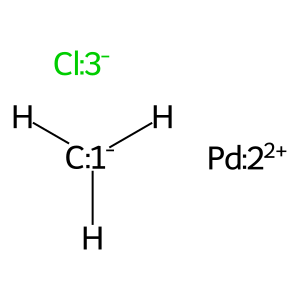

In [37]:
Draw.MolToImage(Chem.AddHs(Chem.MolFromSmiles(fix_valence(Chem.MolToSmiles(s_mol)))))

In [38]:
ylide = "CC(C)(C)P->1(C(C)(C)C)c2(cccc2)[Fe]c2(cccc2)P->(C(C)(C)C)(C(C)(C)C)[Pd]1(Cl)Cl"
s_y = get_BE_matrix(ylide)
print(s_y)

ArgumentError: Python argument types in
    rdkit.Chem.rdmolops.Kekulize(NoneType)
did not match C++ signature:
    Kekulize(RDKit::ROMol {lvalue} mol, bool clearAromaticFlags=False)

In [39]:
sy_mol = Chem.AddHs(BEmatrix_to_mol(Chem.MolFromSmiles(ylide, ps), s_y))

NameError: name 's_y' is not defined

In [40]:
Draw.MolToImage(sy_mol)

NameError: name 'sy_mol' is not defined

[[0. 1. 0. 0.]
 [1. 0. 2. 1.]
 [0. 2. 4. 0.]
 [0. 1. 0. 0.]]
{(1, 1): 0, (2, 2): 0, (3, 3): 4, (4, 4): 0} {(1, 2): 2, (2, 3): 4, (2, 4): 2}


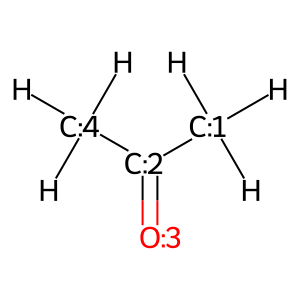

In [44]:
acetone = "[CH3:1][C:2](=[O:3])([CH3:4])"
s__ = get_BE_matrix(acetone)
print(s__)
s__mol = Chem.AddHs(BEmatrix_to_mol(Chem.MolFromSmiles(acetone, ps), s__))
Draw.MolToImage(s__mol)

In [42]:
def isotope_atom_map (rmol):
    atom_map = 1
    for atom in rmol.GetAtoms():
        atom.SetIsotope(atom_map)
        atom_map += 1

    # print(atom_map)
    # print(Chem.MolToSmiles(rmol))
    # Generate the SMILES and molecular representations
    smiles_w_isotope = Chem.MolToSmiles(rmol)
    
    return smiles_w_isotope

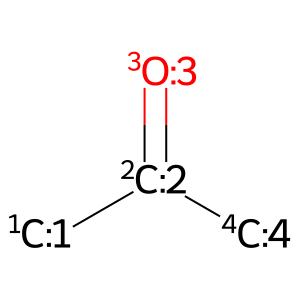

In [367]:
Draw.MolToImage(Chem.MolFromSmiles(isotope_atom_map(Chem.MolFromSmiles(acetone))))